# pRF R²: subject-specific designs vs design A (same fitting code)

Refit of sub-05, sub-14, sub-16 and sub-17 with the common design A (`prfmodel_designA`), compared with the fits with their own designs (`prfmodel`). Same model, same code (prfmodel v2), same data: only the design matrix changes. This isolates the effect of the design from the change of fitting code (prfpy → prfmodel).

| subject | design actually shown (bars) | expected difference |
|---|---|---|
| sub-05 | BarsRightEye run-01 = design B, the 3 other bars runs = design A | RightEye bars tasks only |
| sub-14, sub-17 | all bars runs = design B | all bars tasks, both eyes |
| sub-16 | LE run-01, RE run-01 and RE run-02 reconstructed, LE run-02 = design A | all bars tasks, mostly RightEye |
| all | rings and wedges identical in both fits | **RingsWedges: no difference (control)** |

**Concatenations:** every task of `prf_tasks_eyes_names` (BarsBarsRingsWedges, BarsBars, RingsWedges × left / right eye).
**Regions:** the 8 ROIs of `rois-group-mmp`, all ROIs together, and the **whole cortex** (all vertices of both hemispheres).
**Measures** (per subject × task × region, same vertices in both fits): median R², mean R², % of vertices with R² ≥ `rsqr_th`, and, vertex by vertex, the median of ΔR² = R²(own design) − R²(design A) and the % of vertices improved.

Data: pRF derivative images (`prf_derivatives/*_prf-css_deriv.func.gii`, fsnative), read only; local cache of the R² in `Desktop/fig_od/r2_designA_cache`. Figures in `Desktop/fig_od`.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("{}/../../analysis_code/utils".format(os.getcwd()))
from settings_utils import load_settings
from pycortex_utils import set_pycortex_config_file, get_rois, load_surface_pycortex

# Directories
main_dir = '/Users/uriel/disks/meso_shared'
project_dir = 'amblyo7T_prf'
pp_dir = '{}/{}/derivatives/pp_data'.format(main_dir, project_dir)
fig_dir = '/Users/uriel/Desktop/fig_od'
cache_dir = '{}/r2_designA_cache'.format(fig_dir)
os.makedirs(cache_dir, exist_ok=True)

# Settings
base_dir = os.path.abspath(os.path.join(os.getcwd(), "../../"))
analysis_info = load_settings([os.path.join(base_dir, project_dir, f) for f in
                               ["settings.yml", "prf-analysis.yml", "figure-settings.yml"]])[0]
maps_names_css = analysis_info['maps_names_css']
rsq_idx = maps_names_css.index('prf_rsq')
rsqr_th = analysis_info['rsqr_th']
rois_method = 'rois-group-mmp'
rois = list(analysis_info[rois_method].keys())
tasks = [t for pair in analysis_info['prf_tasks_eyes_names'] for t in pair]
set_pycortex_config_file('{}/{}/derivatives/pp_data/cortex'.format(main_dir, project_dir))

subjects = ['sub-05', 'sub-14', 'sub-16', 'sub-17']
folders = {'own design': 'prfmodel', 'design A': 'prfmodel_designA'}
fspec = '{}/{}/fsnative/{}/prf_derivatives/{}_task-{}_hemi-{}_fmriprep_dct_psc_concat_prf-css_deriv.func.gii'
print('tasks:', tasks)
print('ROIs:', rois)

tasks: ['BarsBarsRingsWedgesRightEye', 'BarsBarsRingsWedgesLeftEye', 'BarsBarsRightEye', 'BarsBarsLeftEye', 'RingsWedgesRightEye', 'RingsWedgesLeftEye']
ROIs: ['V1', 'V2', 'V3', 'V4', 'V3A', 'V3B', 'LO1', 'LO2']


In [2]:
def load_rsq(subject, folder, task):
    """R² of all the fsnative vertices (both hemispheres), cached locally; None if the fit is missing."""
    fns = [fspec.format(pp_dir, subject, folder, subject, task, h) for h in 'LR']
    if not all(os.path.isfile(f) for f in fns):
        return None
    cache_fn = '{}/{}_{}_{}_rsq.npy'.format(cache_dir, subject, folder, task)
    if os.path.isfile(cache_fn) and os.path.getmtime(cache_fn) >= max(os.path.getmtime(f) for f in fns):
        return np.load(cache_fn)
    rsq = load_surface_pycortex(L_fn=fns[0], R_fn=fns[1])['data_concat'][rsq_idx].astype(np.float32)
    np.save(cache_fn, rsq)
    return rsq


def measures(a, b):
    """a = own design, b = design A, same vertices; vertices finite in both fits."""
    ok = np.isfinite(a) & np.isfinite(b)
    a, b = a[ok], b[ok]
    d = a - b
    return {'n_vertices': ok.sum(),
            'median_own': np.median(a), 'median_A': np.median(b),
            'mean_own': np.mean(a), 'mean_A': np.mean(b),
            'pct_above_own': 100 * np.mean(a >= rsqr_th), 'pct_above_A': 100 * np.mean(b >= rsqr_th),
            'median_delta': np.median(d), 'pct_improved': 100 * np.mean(d > 0)}


rows, missing, rsq_store = [], [], {}
for subject in subjects:
    masks = get_rois(subject=subject, surf_format='fsnative', rois_type=rois_method, mask=True, rois=None, hemis=None)
    for task in tasks:
        r = {k: load_rsq(subject, f, task) for k, f in folders.items()}
        if any(v is None for v in r.values()):
            missing.append((subject, task, [k for k, v in r.items() if v is None]))
            continue
        rsq_store[(subject, task)] = r
        regions = {roi: masks[roi] for roi in rois}
        regions['all ROIs'] = np.any([masks[roi] for roi in rois], axis=0)
        regions['whole cortex'] = np.ones(r['own design'].shape, bool)
        for region, m in regions.items():
            rows.append({'subject': subject, 'task': task, 'region': region,
                         **measures(r['own design'][m], r['design A'][m])})
    print('{}: done'.format(subject))
df = pd.DataFrame(rows)
df['ratio_median'] = df.median_own / df.median_A
print('\nMissing fits (subject, task, which):')
for x in missing:
    print('  ', x)
regions_order = rois + ['all ROIs', 'whole cortex']

sub-05: done
sub-14: done
sub-16: done
sub-17: done

Missing fits (subject, task, which):


## Summary table

Median R² with the own design / with design A, and median vertex-wise ΔR², for every subject × task, in all ROIs together and in the whole cortex. RingsWedges must give ΔR² ≈ 0 (same design in both fits).

In [3]:
for region in ['all ROIs', 'whole cortex']:
    print('\n=== {} ==='.format(region))
    t = df[df.region == region].set_index(['subject', 'task'])[
        ['median_own', 'median_A', 'ratio_median', 'median_delta', 'pct_improved', 'pct_above_own', 'pct_above_A']]
    print(t.round(3).to_string())


=== all ROIs ===
                                     median_own  median_A  ratio_median  median_delta  pct_improved  pct_above_own  pct_above_A
subject task                                                                                                                   
sub-05  BarsBarsRingsWedgesRightEye       0.113     0.097         1.156         0.018        78.243         97.573       97.682
        BarsBarsRingsWedgesLeftEye        0.078     0.078         1.000         0.000         0.000         98.159       98.159
        BarsBarsRightEye                  0.110     0.079         1.395         0.040        80.216         97.840       97.446
        BarsBarsLeftEye                   0.089     0.089         1.000         0.000        31.301         97.829       97.679
        RingsWedgesRightEye               0.156     0.156         1.000         0.000        25.349         96.889       96.855
        RingsWedgesLeftEye                0.111     0.111         1.000         0.000 

## ΔR² per ROI, task and subject

Heatmap of the median vertex-wise ΔR² = R²(own design) − R²(design A). Red: the own design fits better. One panel per subject.

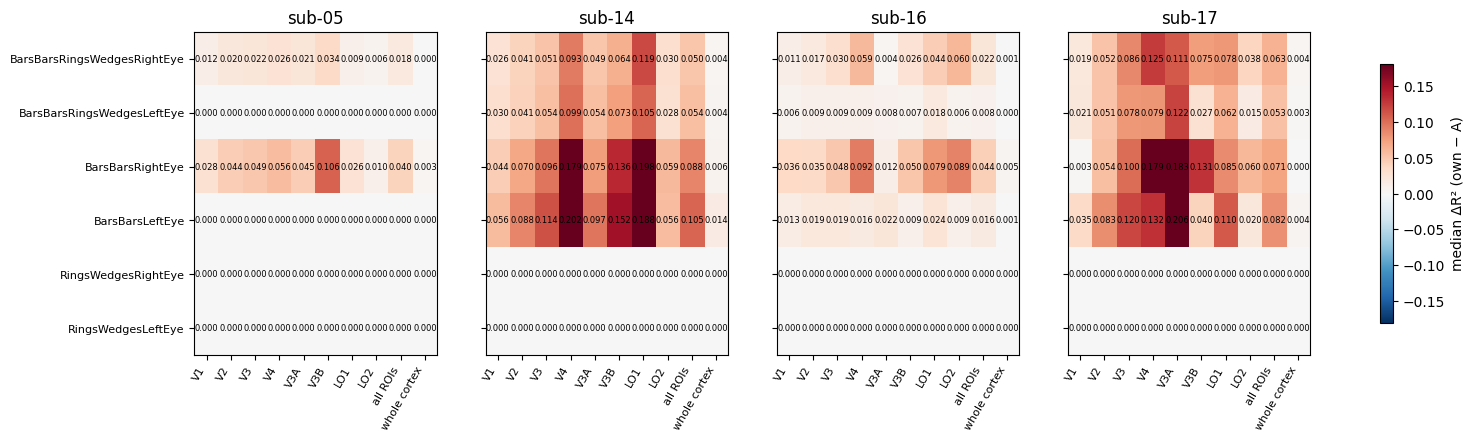

In [7]:
vmax = np.nanpercentile(np.abs(df.median_delta), 98)
fig, axes = plt.subplots(1, len(subjects), figsize=(4.5 * len(subjects), 4.2), sharey=True)
for ax, subject in zip(axes, subjects):
    t = (df[df.subject == subject].pivot(index='task', columns='region', values='median_delta')
         .reindex(index=tasks, columns=regions_order))
    im = ax.imshow(t.values, cmap='RdBu_r', vmin=-vmax, vmax=vmax, aspect='auto')
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            if np.isfinite(t.values[i, j]):
                ax.text(j, i, '{:.3f}'.format(t.values[i, j]), ha='center', va='center', fontsize=6)
    ax.set_xticks(range(len(regions_order)))
    ax.set_xticklabels(regions_order, rotation=60, ha='right', fontsize=8)
    ax.set_yticks(range(len(tasks)))
    ax.set_yticklabels(tasks, fontsize=8)
    ax.set_title(subject)
fig.colorbar(im, ax=axes, shrink=0.8, label='median ΔR² (own − A)')
fig.savefig('{}/r2_designA_delta_heatmap.pdf'.format(fig_dir), bbox_inches='tight')
plt.show()

## Median R² with each design, per ROI

Bars: median R² with the own design (solid) and with design A (hatched), per task (rows) and subject (columns).

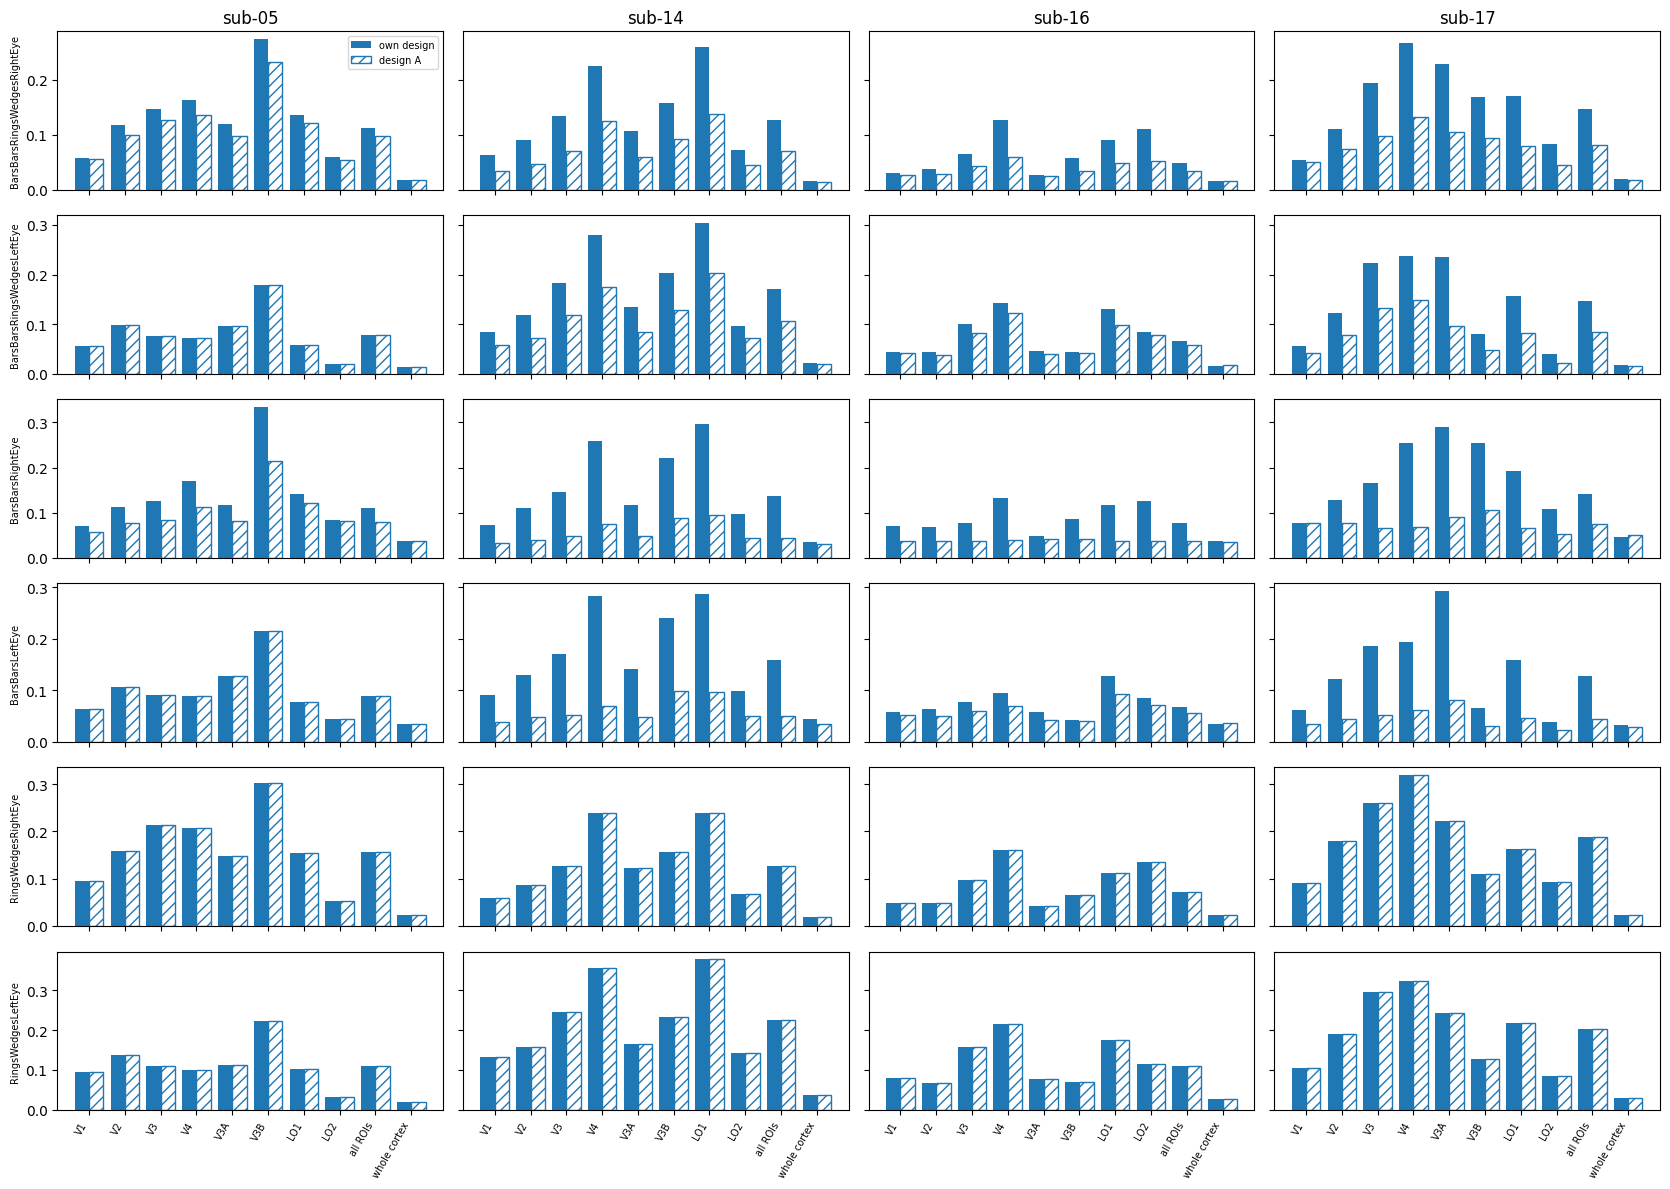

In [5]:
fig, axes = plt.subplots(len(tasks), len(subjects), figsize=(4.2 * len(subjects), 2.0 * len(tasks)), sharey='row', sharex=True)
x = np.arange(len(regions_order))
for c, subject in enumerate(subjects):
    for r, task in enumerate(tasks):
        ax = axes[r, c]
        t = df[(df.subject == subject) & (df.task == task)].set_index('region').reindex(regions_order)
        ax.bar(x - 0.2, t.median_own, 0.4, color='tab:blue', label='own design')
        ax.bar(x + 0.2, t.median_A, 0.4, color='white', edgecolor='tab:blue', hatch='///', label='design A')
        if r == 0:
            ax.set_title(subject)
        if c == 0:
            ax.set_ylabel(task, fontsize=7)
axes[0, 0].legend(fontsize=7)
for ax in axes[-1]:
    ax.set_xticks(x)
    ax.set_xticklabels(regions_order, rotation=60, ha='right', fontsize=7)
plt.tight_layout()
fig.savefig('{}/r2_designA_median_bars.pdf'.format(fig_dir), bbox_inches='tight')
plt.show()

## Vertex by vertex, whole cortex

R² with design A (x) vs own design (y) for every vertex of the cortex, BarsBarsRingsWedges of each eye. Points above the diagonal are better fitted with the own design.

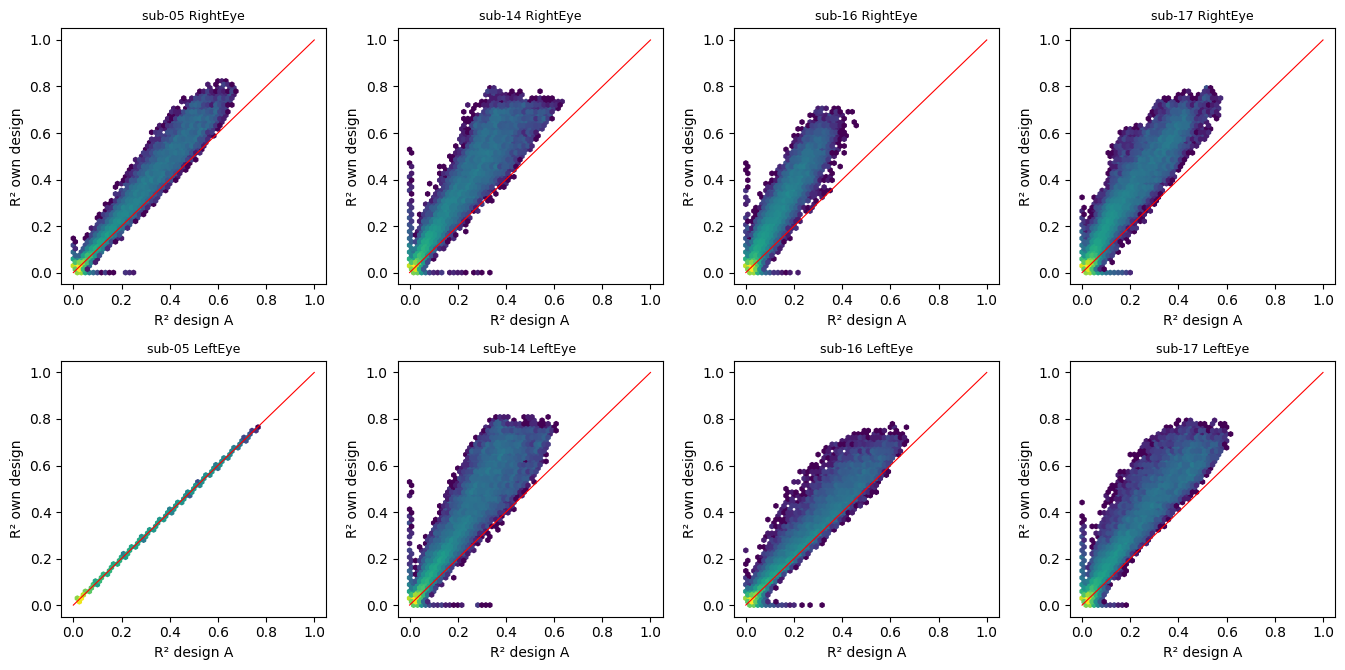

In [6]:
show = [t for t in tasks if t.startswith('BarsBarsRingsWedges')]
fig, axes = plt.subplots(len(show), len(subjects), figsize=(3.4 * len(subjects), 3.4 * len(show)))
axes = np.atleast_2d(axes)
for c, subject in enumerate(subjects):
    for r, task in enumerate(show):
        ax = axes[r, c]
        if (subject, task) not in rsq_store:
            ax.axis('off')
            continue
        a, b = rsq_store[(subject, task)]['own design'], rsq_store[(subject, task)]['design A']
        ok = np.isfinite(a) & np.isfinite(b) & ((a > 0.02) | (b > 0.02))
        ax.hexbin(b[ok], a[ok], gridsize=60, bins='log', cmap='viridis', extent=(0, 1, 0, 1))
        ax.plot([0, 1], [0, 1], 'r', lw=0.8)
        ax.set_title('{} {}'.format(subject, task.replace('BarsBarsRingsWedges', '')), fontsize=9)
        ax.set_xlabel('R² design A')
        ax.set_ylabel('R² own design')
plt.tight_layout()
fig.savefig('{}/r2_designA_vertex_scatter.pdf'.format(fig_dir), bbox_inches='tight')
plt.show()

## Reading guide

- **RingsWedges** (control): same design in both fits, ΔR² must be ≈ 0. A difference there would point to something else than the design (e.g. a different fit run).
- **sub-05**: a difference is expected only for the RightEye bars tasks (BarsBarsRightEye, BarsBarsRingsWedgesRightEye), where one run in four differs.
- **sub-14, sub-17**: all bars tasks of both eyes; **sub-16**: all bars tasks, more for the right eye (2 runs out of 2 reconstructed vs 1 out of 2 for the left eye).
- Positive ΔR² with the own design = the subject-specific design describes the stimulus actually shown better than the common design A; the size of the gain, compared with the earlier prfpy vs prfmodel comparison (`r2_design_comparison.ipynb`), tells how much of that earlier gain was due to the design rather than to the fitting code.